## Data cleaning notes

**Source:** eia_coal_consumption_quality_2020_2025.csv. Original kept unchanged as `coal`; all edits made on `clean`.

**Units:** consumption, receipts, stocks in short tons; price in dollars per short ton; ash and sulfur in percent by weight; heat content in million Btu per short ton.

**Changes**
1. `sector` and `location` converted to consistent types (`location` to string).
2. Zeros treated as missing and set to NaN: price, ash and sulfur where receipts = 0; heat content where consumption = 0; any remaining price zeros (one Utah row). Zeros in consumption and receipts kept as real.
3. Heat content for sectors 8, 9, 10 was on a different scale (consistent with Btu per pound) and was converted by x 2000 / 1,000,000. **Inferred from the data, not confirmed by the source.**
4. `heat-content-units` was mislabeled as "average sulfur percent by weight"; corrected to "million Btu per short ton".
**Structure**
- Sector 94 = sectors 2 + 3, and sector 98 = sectors 1 + 94 (verified, all rows). Analysis uses leaf sectors 1, 2, 3, 8, 9, 10 only.
- Region rows (including Pacific, PCC, PCN, and the US total) overlap with states (US total verified = sum of states). Analysis uses the 50 state-level locations (48 states, DC, PR) only. MA and VT have no rows.
- No duplicate period/location/sector rows.

**Caveats**
- `stocks` is reported almost only for sectors 8, 9, 10; missing elsewhere means not reported.
- Price, ash, sulfur, heat content are per-ton values: use weighted averages (by receipts or consumption), never plain sums.

In [2]:
import pandas as pd

coal = pd.read_csv("eia_coal_consumption_quality_2020_2025.csv")
print(coal.shape)

(1750, 19)


In [ ]:
coal.head()
coal.info()
coal.isna().sum()

<class 'pandas.DataFrame'>
RangeIndex: 1750 entries, 0 to 1749
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   period                1750 non-null   int64  
 1   location              1750 non-null   str    
 2   stateDescription      1750 non-null   str    
 3   sector                1750 non-null   int64  
 4   sectorDescription     1750 non-null   str    
 5   ash-content           1558 non-null   float64
 6   consumption           1735 non-null   float64
 7   heat-content          1723 non-null   float64
 8   price                 667 non-null    float64
 9   receipts              1570 non-null   float64
 10  stocks                535 non-null    float64
 11  sulfur-content        1558 non-null   float64
 12  ash-content-units     1750 non-null   str    
 13  consumption-units     1750 non-null   str    
 14  heat-content-units    1750 non-null   str    
 15  price-units           1750 non-n

period                     0
location                   0
stateDescription           0
sector                     0
sectorDescription          0
ash-content              192
consumption               15
heat-content              27
price                   1083
receipts                 180
stocks                  1215
sulfur-content           192
ash-content-units          0
consumption-units          0
heat-content-units         0
price-units                0
receipts-units             0
stocks-units               0
sulfur-content-units       0
dtype: int64

In [ ]:
coal.head(10)

,period,location,stateDescription,sector,sectorDescription,ash-content,consumption,heat-content,price,receipts,stocks,sulfur-content,ash-content-units,consumption-units,heat-content-units,price-units,receipts-units,stocks-units,sulfur-content-units
0,2020,90,Pacific,1,Electric Utility,6.30,1541461.0,16.2558,42.25,873007.0,NaN,0.21,average ash percent by weight,short tons,average sulfur percent by weight,dollars per short ton,short tons,short tons,average sulfur percent by weight
1,2020,90,Pacific,2,IPP Non-CHP,8.36,3476488.0,16.6534,NaN,3525648.0,NaN,0.40,average ash percent by weight,short tons,average sulfur percent by weight,dollars per short ton,short tons,short tons,average sulfur percent by weight
2,2020,90,Pacific,3,IPP CHP,4.92,890674.0,18.6360,NaN,725275.0,NaN,0.27,average ash percent by weight,short tons,average sulfur percent by weight,dollars per short ton,short tons,short tons,average sulfur percent by weight
3,2020,90,Pacific,94,Independent Power Producers,7.70,4367162.0,17.0577,NaN,4250923.0,NaN,0.38,average ash percent by weight,short tons,average sulfur percent by weight,dollars per short ton,short tons,short tons,average sulfur percent by weight
4,2020,90,Pacific,98,Electric Power,7.48,5908623.0,16.8485,NaN,5123930.0,NaN,0.35,average ash percent by weight,short tons,average sulfur percent by weight,dollars per short ton,short tons,short tons,average sulfur percent by weight
5,2020,AK,Alaska,1,Electric Utility,9.43,556171.0,14.5312,49.26,347822.0,NaN,0.15,average ash percent by weight,short tons,average sulfur percent by weight,dollars per short ton,short tons,short tons,average sulfur percent by weight
6,2020,AK,Alaska,10,Other Industrial,NaN,1315.0,NaN,NaN,1315.0,NaN,NaN,average ash percent by weight,short tons,average sulfur percent by weight,dollars per short ton,short tons,short tons,average sulfur percent by weight
7,2020,AK,Alaska,3,IPP CHP,0.00,220848.0,15.0235,NaN,0.0,NaN,0.00,average ash percent by weight,short tons,average sulfur percent by weight,dollars per short ton,short tons,short tons,average sulfur percent by weight
8,2020,AK,Alaska,8,Commercial and Institutional,7.53,472932.0,7514.0000,NaN,464609.0,109294.0,0.16,average ash percent by weight,short tons,average sulfur percent by weight,dollars per short ton,short tons,short tons,average sulfur percent by weight
9,2020,AK,Alaska,94,Independent Power Producers,0.00,220848.0,15.0235,0.00,0.0,NaN,0.00,average ash percent by weight,short tons,average sulfur percent by weight,dollars per short ton,short tons,short tons,average sulfur percent by weight


In [ ]:
clean = coal.copy()
clean["sector"] = clean["sector"].astype("category")
display(clean.head(10))

,period,location,stateDescription,sector,sectorDescription,ash-content,consumption,heat-content,price,receipts,stocks,sulfur-content,ash-content-units,consumption-units,heat-content-units,price-units,receipts-units,stocks-units,sulfur-content-units
0,2020,90,Pacific,1,Electric Utility,6.30,1541461.0,16.2558,42.25,873007.0,NaN,0.21,average ash percent by weight,short tons,average sulfur percent by weight,dollars per short ton,short tons,short tons,average sulfur percent by weight
1,2020,90,Pacific,2,IPP Non-CHP,8.36,3476488.0,16.6534,NaN,3525648.0,NaN,0.40,average ash percent by weight,short tons,average sulfur percent by weight,dollars per short ton,short tons,short tons,average sulfur percent by weight
2,2020,90,Pacific,3,IPP CHP,4.92,890674.0,18.6360,NaN,725275.0,NaN,0.27,average ash percent by weight,short tons,average sulfur percent by weight,dollars per short ton,short tons,short tons,average sulfur percent by weight
3,2020,90,Pacific,94,Independent Power Producers,7.70,4367162.0,17.0577,NaN,4250923.0,NaN,0.38,average ash percent by weight,short tons,average sulfur percent by weight,dollars per short ton,short tons,short tons,average sulfur percent by weight
4,2020,90,Pacific,98,Electric Power,7.48,5908623.0,16.8485,NaN,5123930.0,NaN,0.35,average ash percent by weight,short tons,average sulfur percent by weight,dollars per short ton,short tons,short tons,average sulfur percent by weight
5,2020,AK,Alaska,1,Electric Utility,9.43,556171.0,14.5312,49.26,347822.0,NaN,0.15,average ash percent by weight,short tons,average sulfur percent by weight,dollars per short ton,short tons,short tons,average sulfur percent by weight
6,2020,AK,Alaska,10,Other Industrial,NaN,1315.0,NaN,NaN,1315.0,NaN,NaN,average ash percent by weight,short tons,average sulfur percent by weight,dollars per short ton,short tons,short tons,average sulfur percent by weight
7,2020,AK,Alaska,3,IPP CHP,0.00,220848.0,15.0235,NaN,0.0,NaN,0.00,average ash percent by weight,short tons,average sulfur percent by weight,dollars per short ton,short tons,short tons,average sulfur percent by weight
8,2020,AK,Alaska,8,Commercial and Institutional,7.53,472932.0,7514.0000,NaN,464609.0,109294.0,0.16,average ash percent by weight,short tons,average sulfur percent by weight,dollars per short ton,short tons,short tons,average sulfur percent by weight
9,2020,AK,Alaska,94,Independent Power Producers,0.00,220848.0,15.0235,0.00,0.0,NaN,0.00,average ash percent by weight,short tons,average sulfur percent by weight,dollars per short ton,short tons,short tons,average sulfur percent by weight


Replaces zero value with NaN

In [ ]:
import numpy as np

r0 = clean["receipts"] == 0
clean.loc[r0, ["print", "ash-content", "sulfur-content"]] = np.nan

c0 = clean["consumption"] == 0
clean.loc[c0, "heat-content"] = np.nan

In [ ]:
r0 = coal["receipts"] == 0
p0 = coal["price"] == 0

print((p0 & r0).sum())
print((p0 & ~r0).sum())
print(coal[p0 & ~r0][["stateDescription", "sectorDescription", "receipts", "price"]])

16
1
    stateDescription            sectorDescription  receipts  price
260             Utah  Independent Power Producers  322189.0    0.0


In [ ]:
clean["price"] = clean["price"].replace(0, np.nan)

heat-content for sectors 8, 9, and 10 was reported on a different scale and was converted to millions Btu per short ton by multiplying by 2000/1,000,000.

In [ ]:
m = mask & clean["heat-content"].notna()
clean.loc[m, "heat-content"] = coal.loc[m, "heat-content"] * 2000 / 1_000_000

Label correction for "heat-content-units", which was "average sulfur percent by weight"

In [ ]:
clean["heat-content-units"] = "million Btu per short ton"

In [ ]:
clean["location"] = clean["location"].astype(str)
print(clean[["location", "stateDescription"]].drop_duplicates())

    location    stateDescription
0         90             Pacific
5         AK              Alaska
11        AL             Alabama
15        AR            Arkansas
20        AZ             Arizona
..       ...                 ...
274       WI           Wisconsin
278      WNC  West North Central
284      WSC  West South Central
289       WV       West Virginia
296       WY             Wyoming

[62 rows x 2 columns]


In [ ]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


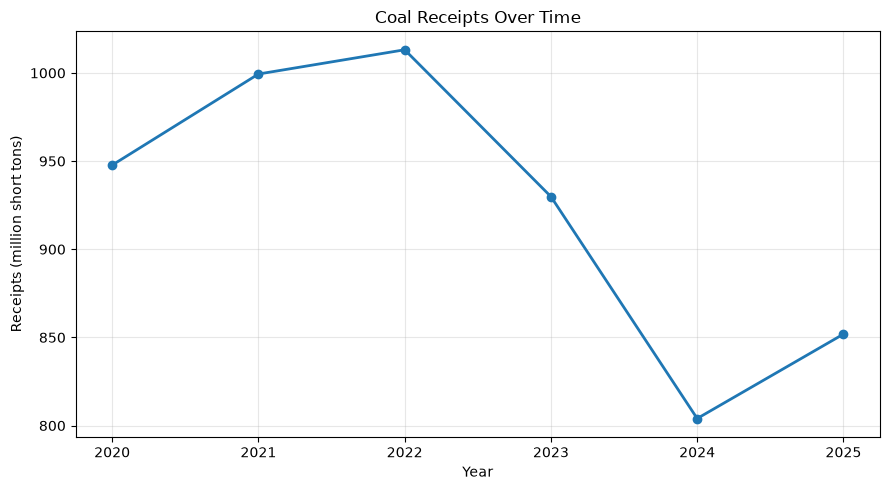

In [ ]:
# Use state-level leaf sectors to avoid double-counting regional and aggregate rows
import matplotlib.pyplot as plt

receipts_over_time = (
    clean[
        (~clean["location"].isin(region_codes))
        & (clean["sector"].astype(str).isin(leaf))
    ]
    .groupby("period", as_index=False)["receipts"]
    .sum()
)

receipts_over_time["receipts_million_tons"] = (
    receipts_over_time["receipts"] / 1_000_000
)

plt.figure(figsize=(9, 5))
plt.plot(
    receipts_over_time["period"],
    receipts_over_time["receipts_million_tons"],
    marker="o",
    linewidth=2
)
plt.title("Coal Receipts Over Time")
plt.xlabel("Year")
plt.ylabel("Receipts (million short tons)")
plt.grid(True, alpha=0.3)
plt.xticks(receipts_over_time["period"])
plt.tight_layout()
plt.show()

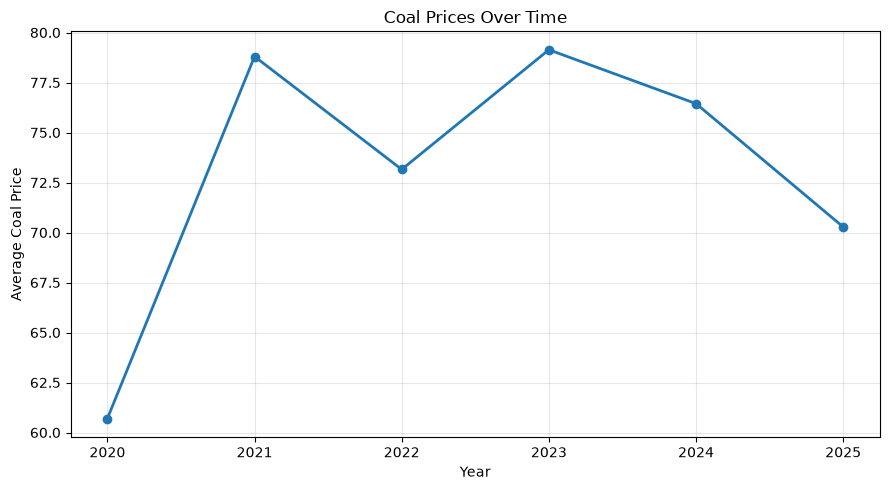

In [ ]:
coal_prices_over_time = (
    clean[
        (~clean["location"].isin(region_codes))
        & (clean["sector"].astype(str).isin(leaf))
    ]
    .groupby("period", as_index=False)["price"]
    .mean()
)

plt.figure(figsize=(9, 5))
plt.plot(
    coal_prices_over_time["period"],
    coal_prices_over_time["price"],
    marker="o",
    linewidth=2
)

plt.title("Coal Prices Over Time")
plt.xlabel("Year")
plt.ylabel("Average Coal Price")
plt.grid(True, alpha=0.3)
plt.xticks(coal_prices_over_time["period"])
plt.tight_layout()
plt.show()

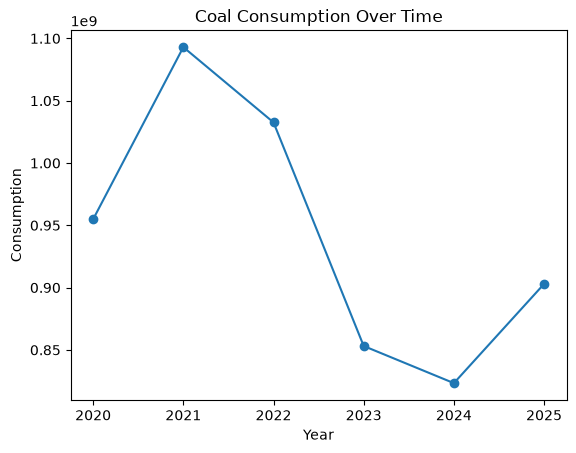

In [ ]:
consumption_over_time = (
    clean[
        (~clean["location"].isin(region_codes))
        & (clean["sector"].astype(str).isin(leaf))
    ]
    .groupby("period", as_index=False)["consumption"]
    .sum()
)

plt.plot(
    consumption_over_time["period"],
    consumption_over_time["consumption"],
    marker="o"
)

plt.title("Coal Consumption Over Time")
plt.xlabel("Year")
plt.ylabel("Consumption")
plt.show()

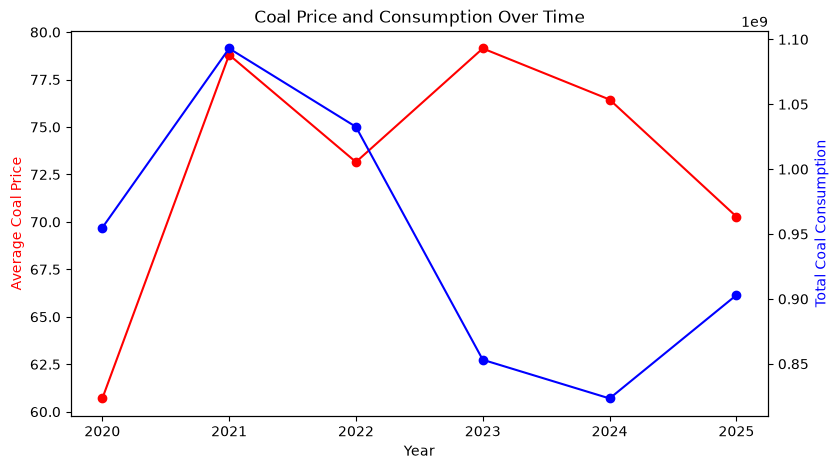

In [ ]:
import matplotlib.pyplot as plt

trend = (
    clean[
        (~clean["location"].isin(region_codes))
        & (clean["sector"].astype(str).isin(leaf))
    ]
    .groupby("period", as_index=False)
    .agg({
        "price": "mean",
        "consumption": "sum"
    })
)

fig, ax1 = plt.subplots(figsize=(9, 5))

ax1.plot(trend["period"], trend["price"], marker="o", color="red")
ax1.set_xlabel("Year")
ax1.set_ylabel("Average Coal Price", color="red")

ax2 = ax1.twinx()
ax2.plot(trend["period"], trend["consumption"], marker="o", color="blue")
ax2.set_ylabel("Total Coal Consumption", color="blue")

plt.title("Coal Price and Consumption Over Time")
plt.show()

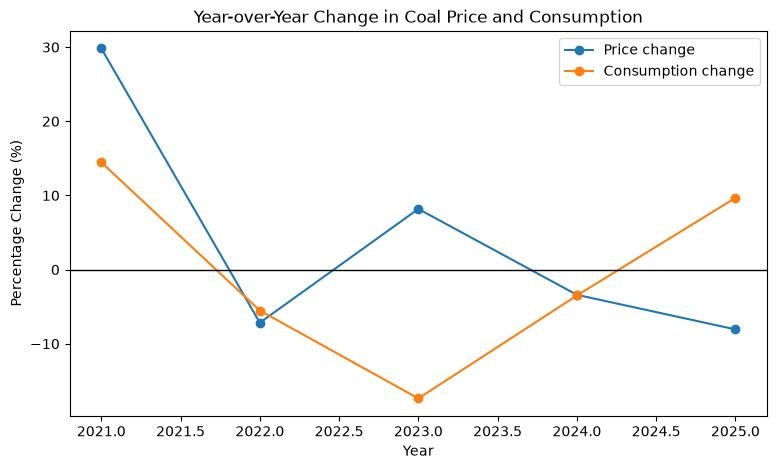

In [ ]:
yearly = (
    clean[
        (~clean["location"].isin(region_codes))
        & (clean["sector"].astype(str).isin(leaf))
    ]
    .groupby("period", as_index=False)
    .agg({
        "price": "mean",
        "consumption": "sum"
    })
    .sort_values("period")
)

yearly["price_change_pct"] = yearly["price"].pct_change() * 100
yearly["consumption_change_pct"] = yearly["consumption"].pct_change() * 100

plt.figure(figsize=(9, 5))

plt.plot(
    yearly["period"],
    yearly["price_change_pct"],
    marker="o",
    label="Price change"
)

plt.plot(
    yearly["period"],
    yearly["consumption_change_pct"],
    marker="o",
    label="Consumption change"
)

plt.axhline(0, color="black", linewidth=1)
plt.title("Year-over-Year Change in Coal Price and Consumption")
plt.xlabel("Year")
plt.ylabel("Percentage Change (%)")
plt.legend()
plt.show()

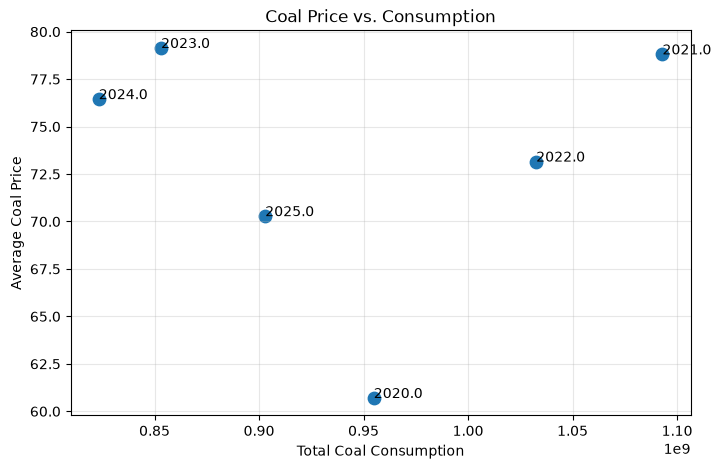

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    yearly["consumption"],
    yearly["price"],
    s=80
)

for _, row in yearly.iterrows():
    plt.annotate(
        row["period"],
        (row["consumption"], row["price"])
    )

plt.title("Coal Price vs. Consumption")
plt.xlabel("Total Coal Consumption")
plt.ylabel("Average Coal Price")
plt.grid(True, alpha=0.3)
plt.show()

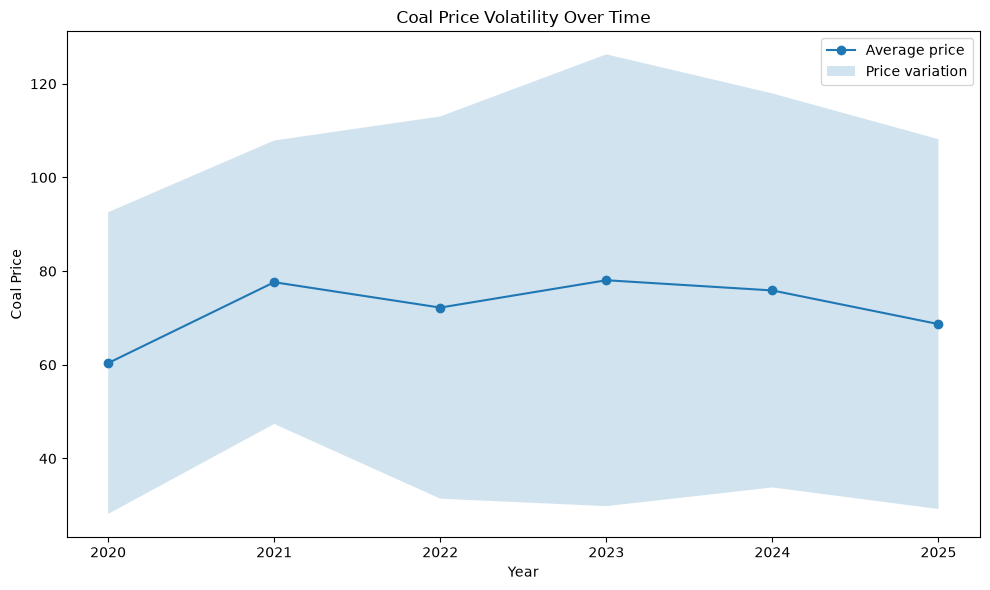

In [ ]:
import matplotlib.pyplot as plt

state_prices = (
    clean[
        (~clean["location"].isin(region_codes))
        & (~clean["location"].isin(["US", "USA"]))
        & (clean["sector"].astype(str).isin(leaf))
    ]
    .groupby("period", as_index=False)["price"]
    .agg(["mean", "std"])
    .reset_index()
)

plt.figure(figsize=(10, 6))

plt.plot(
    state_prices["period"],
    state_prices["mean"],
    marker="o",
    label="Average price"
)

plt.fill_between(
    state_prices["period"],
    state_prices["mean"] - state_prices["std"],
    state_prices["mean"] + state_prices["std"],
    alpha=0.2,
    label="Price variation"
)

plt.title("Coal Price Volatility Over Time")
plt.xlabel("Year")
plt.ylabel("Coal Price")
plt.legend()
plt.tight_layout()
plt.show()